# Case Study 10 — Modelling Insurance Claim Cost

**Regression assumptions and diagnostics · residual, Q-Q, scale-location and leverage plots · Cook's distance ·
heteroscedasticity tests and robust standard errors · Box-Cox, square-root and log transforms · polynomial terms and
component-plus-residual plots · retransformation bias and the smearing estimator · gamma GLM · mean-variance
relationship · capped outcomes · reserve uncertainty**

| | |
|---|---|
| **Domain** | Health insurance: claim-cost pricing and reserving |
| **Stakeholders** | Appointed Actuary, Head of Health Claims |
| **Difficulty** | Intermediate–Advanced |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 06 (simple regression, log models), Case 07 (multiple regression) |
| **Data** | 6,000 settled hospitalisation claims |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. A **diagnostic workflow** for regression: what each plot and test checks, and what to do when it fails.
2. How to find **influential points** with Cook's distance, and how to decide between "data error" and "genuine but
   extreme".
3. How to fix **non-constant variance** and **skew**: robust standard errors, transformations, or a different model.
4. Why a log model **under-predicts totals** unless you correct it, and how the **gamma GLM** avoids the problem.

## Section 1 — Business context

You are a data scientist supporting the **Appointed Actuary** of a health insurer. Two uses need a claim-cost model:
- **Pricing**: how much more does a cardiac claim, a private room, or a smoker cost?
- **Reserving**: about 1,500 claims have been pre-authorised but not yet settled. The insurer must hold enough money
  for them, and the reserve is a **total in ₹**.

The analytics team fitted an ordinary regression on the raw claim amount. The Appointed Actuary writes:

> *"The model explains barely anything, it predicts negative costs for some claims, and its errors are enormous for
> big claims. Someone then tried a log model, but its predicted total came out well below what we actually paid. I
> need a model I can defend to the regulator: tell me which assumptions fail, what to do about it, and how much to
> reserve, with a range."*

## Section 2 — Business questions

1. What drives claim cost (for pricing)?
2. Can we trust the current regression on raw ₹? Which assumptions fail?
3. What should we do about the very large claims that dominate the model?
4. Which model gives an accurate **total** for reserving, and why did the log model under-reserve?
5. How much should we reserve for the 1,500 open claims, and how uncertain is that figure?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Cost drivers | Multiplicative effects of procedure, room, hospital, LOS, age, smoker, diabetic | Regression on log scale / gamma GLM with log link |
| 2 | Trust the raw model? | Linearity, constant variance, normality, influence | Residual plots, Breusch-Pagan, RESET, Q-Q, Cook's distance |
| 3 | Very large claims | Data errors or genuine extremes? Influence on coefficients | Cook's distance, business-rule checks, refit with/without |
| 4 | Accurate total | Bias of naive back-transformation; mean model vs median model | Smearing estimator, gamma GLM, holdout totals |
| 5 | Reserve and range | Distribution of the **sum** of future claims | Simulation from the fitted gamma model with parameter uncertainty |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.nonparametric.smoothers_lowess import lowess

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "10_insurance_claim_cost"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1010)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
lfmt = thousands_formatter("₹", "L", 1e5, 0)
crore = lambda v: f"₹{v / 1e7:,.2f} Cr"

def pct(b):
    return 100 * (np.exp(b) - 1)

## Section 4 — Load the data

In [2]:
claims = pd.read_csv(PATHS["data"] / "health_claims.csv")
print(f"{claims.shape[0]:,} claims × {claims.shape[1]} columns;  duplicates: {claims['claim_id'].duplicated().sum()};  "
      f"missing: {claims.isna().sum().sum()}")
display(claims.head())
CATS = {"procedure_category": ["Medical management", "Day-care", "Maternity", "Surgical", "Orthopaedic", "Cardiac", "Oncology"],
        "room_type": ["General ward", "Semi-private", "Private", "Suite"],
        "hospital_type": ["Network-metro", "Network-non-metro", "Non-network"]}
for c, levels in CATS.items():
    claims[c] = pd.Categorical(claims[c], categories=levels)     # first level = reference category
claims["log_claim"] = np.log(claims["claim_amount"])
claims["log_los"] = np.log(claims["preauth_estimated_los"])
claims["age_c"] = claims["age"] - 45                              # centred age (for the squared term)
claims[["age", "preauth_estimated_los", "sum_insured", "claim_amount"]].describe(percentiles=[0.5, 0.9, 0.99]).T

6,000 claims × 10 columns;  duplicates: 0;  missing: 0


,claim_id,age,procedure_category,room_type,hospital_type,preauth_estimated_los,smoker,diabetic,sum_insured,claim_amount
0,HC10100000,37,Medical management,Private,Network-non-metro,3,0,0,2500000,82590
1,HC10100001,21,Medical management,Semi-private,Non-network,4,0,0,1000000,39800
2,HC10100002,49,Surgical,General ward,Network-non-metro,2,1,0,300000,133370
3,HC10100003,18,Day-care,General ward,Network-metro,1,1,0,1000000,7000
4,HC10100004,35,Medical management,Private,Network-metro,9,0,0,2500000,137120


,count,mean,std,min,50%,90%,99%,max
age,"6,000.0000",45.2340,14.5599,18.0000,45.0000,65.0000,81.0000,85.0000
preauth_estimated_los,"6,000.0000",4.1917,2.6277,1.0000,4.0000,8.0000,11.0000,15.0000
sum_insured,"6,000.0000","772,416.6667","630,592.6585","300,000.0000","500,000.0000","1,150,000.0000","2,500,000.0000","2,500,000.0000"
claim_amount,"6,000.0000","139,861.2567","424,420.4639","1,000.0000","86,835.0000","300,000.0000","657,925.4000","22,427,000.0000"


Columns: age; **procedure category** (nominal, 7 levels); **room type** (ordinal, 4 levels); **hospital type**
(nominal, 3); pre-authorisation length-of-stay estimate; smoker; diabetic; **sum insured** (the policy's maximum
payout); and the settled **claim amount**. Note the maximum claim of over ₹2 crore on policies whose sum insured is
at most ₹25 lakh. We will come back to that.

## Section 5 — Descriptive statistics

In [3]:
ca = claims["claim_amount"]
print(f"mean {fmt_money(ca.mean())}, median {fmt_money(ca.median())}, skewness {stats.skew(ca):.1f}, "
      f"top 1% of claims = {ca[ca >= ca.quantile(0.99)].sum() / ca.sum():.0%} of all money paid")
by_proc = claims.groupby("procedure_category", observed=True)["claim_amount"].agg(
    n="size", median="median", mean="mean", p90=lambda s: s.quantile(0.9), cv=lambda s: s.std() / s.mean())
save_table(by_proc, "cost_by_procedure", PATHS["tables"])
by_proc

mean ₹139,861, median ₹86,835, skewness 39.6, top 1% of claims = 13% of all money paid


,n,median,mean,p90,cv
procedure_category,,,,,
Medical management,1994,"68,270.0000","100,142.3069","172,030.0000",5.1364
Day-care,569,"28,920.0000","64,979.2794","64,672.0000",11.2130
Maternity,718,"54,275.0000","65,507.4373","125,591.0000",0.6914
Surgical,1175,"110,020.0000","150,873.7872","273,482.0000",2.5631
Orthopaedic,613,"148,610.0000","180,200.9951","332,678.0000",0.7846
Cardiac,609,"236,930.0000","270,360.2791","500,000.0000",0.6506
Oncology,322,"300,000.0000","320,145.6832","506,849.0000",0.5891


**Observation.** Claim cost is heavily **right-skewed**: the mean is well above the median, and the top 1% of claims
account for a large share of all money paid (inflated here by suspicious values; see Section 9). Costs vary
enormously by procedure: oncology and cardiac claims cost several times medical-management claims. For maternity, orthopaedic, cardiac and oncology claims the
coefficient of variation (SD ÷ mean) is about 0.6–0.8, so **bigger procedures have bigger spreads in ₹**: a first
hint that variance grows with the mean. Medical management, day-care and surgical show absurd CVs (2.5 to 11):
a warning sign that a few impossible values sit in those groups (Section 9).

## Section 6 — Visualisation

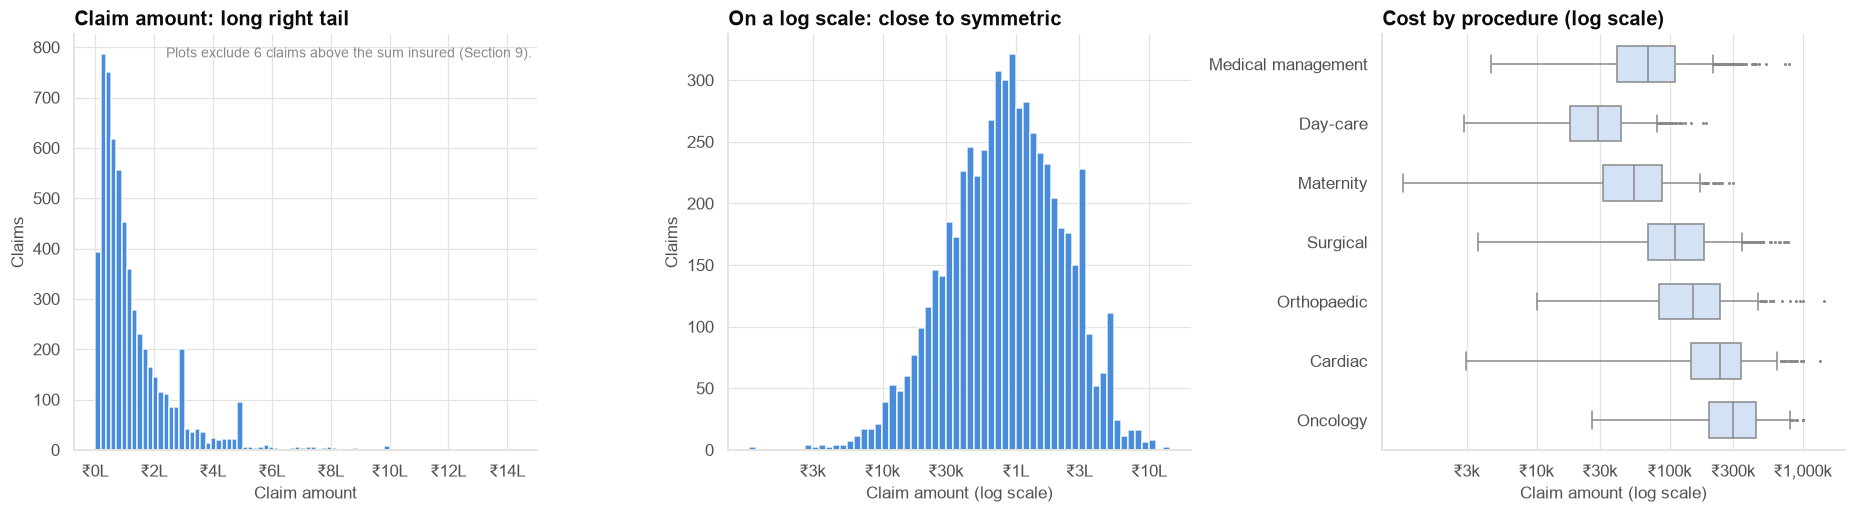

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
clean_view = claims[claims["claim_amount"] <= claims["sum_insured"]]
ax = axes[0]
ax.hist(clean_view["claim_amount"], bins=80, color=PRIMARY, alpha=0.85)
ax.xaxis.set_major_formatter(lfmt)
ax.set(title="Claim amount: long right tail", xlabel="Claim amount", ylabel="Claims")
ax = axes[1]
ax.hist(np.log10(clean_view["claim_amount"]), bins=60, color=PRIMARY, alpha=0.85)
ax.set_xticks(np.log10([3e3, 1e4, 3e4, 1e5, 3e5, 1e6]), ["₹3k", "₹10k", "₹30k", "₹1L", "₹3L", "₹10L"])
ax.set(title="On a log scale: close to symmetric", xlabel="Claim amount (log scale)", ylabel="Claims")
ax = axes[2]
sns.boxplot(data=clean_view, y="procedure_category", x="claim_amount", ax=ax, color="#cde2fb", fliersize=1, width=0.6,
            order=CATS["procedure_category"])
ax.set_xscale("log"); ax.xaxis.set_major_formatter(kfmt); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([3e3, 1e4, 3e4, 1e5, 3e5, 1e6])
ax.set(title="Cost by procedure (log scale)", xlabel="Claim amount (log scale)", ylabel="")
add_note(axes[0], "Plots exclude 6 claims above the sum insured (Section 9).", "upper right")
fig.tight_layout()
save_fig(fig, "fig01_claim_distribution", PATHS["figures"])
plt.show()

**Observation.** On the ₹ scale, the distribution has a long right tail; on the log scale it is roughly symmetric.
Procedure differences look like **multiplicative shifts** (similar spreads on the log scale).

**Interpretation.** Multiplicative effects + right skew + spread growing with the mean are the classic signature of
cost data. A straight-line model on raw ₹ assumes **additive** effects and **constant spread**. We expect it to fail,
and the diagnostics will show exactly how.

## Section 7 — Method selection: the diagnostic workflow

Every linear-regression result relies on assumptions. Each one has a check and a fix:

| Assumption | What breaks if it fails | Check | Typical fix |
|---|---|---|---|
| **Linearity** (right functional form) | Biased coefficients and predictions | Residuals vs fitted (curve), component-plus-residual plots, RESET test | Transform X (log, polynomial, spline) or Y |
| **Constant variance** (homoscedasticity) | Wrong SEs, p-values, CIs, prediction intervals | Residuals vs fitted (funnel), scale-location plot, Breusch-Pagan test | Robust (HC3) SEs; transform Y; model the variance (GLM) |
| **Normal errors** | Small samples: wrong p-values. All samples: wrong prediction intervals | Q-Q plot | Transform Y; bootstrap; GLM with a suitable distribution |
| **Independence** | SEs too small | Study design; residuals over time or by cluster | Cluster-robust SEs, mixed models (Case 25 for time) |
| **No undue influence** | One or a few points drive the result | Leverage, studentised residuals, **Cook's distance** | Check data; fix errors; report with/without |

We follow the workflow on the team's model (raw ₹), then fix each failure.

## Section 8 — Model A: ordinary regression on raw ₹ (the team's model)

Model A on ALL raw claims: R² = 0.051


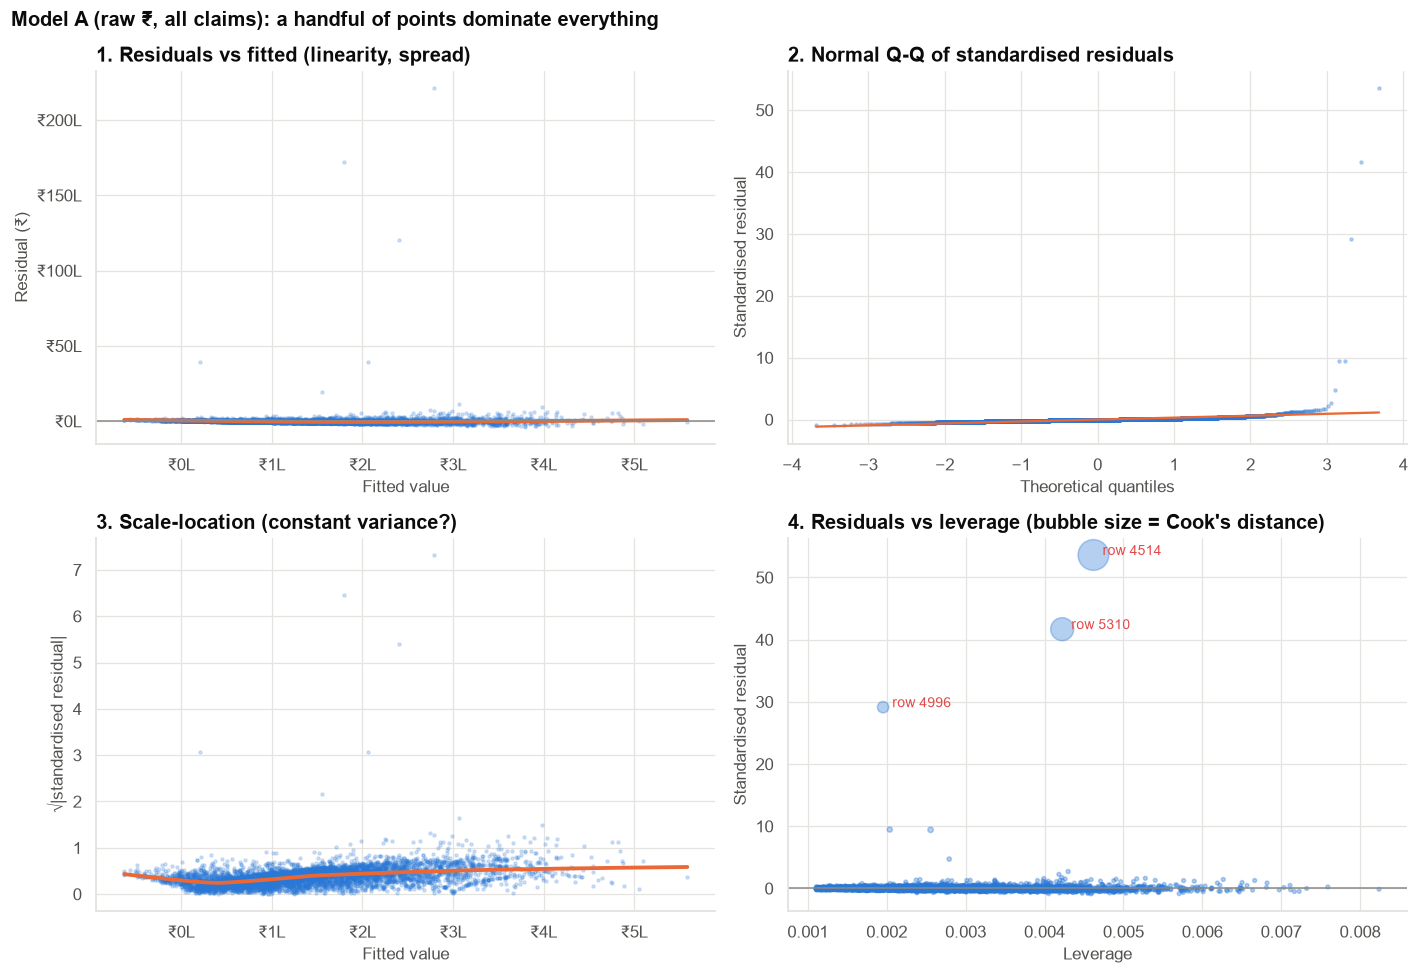

In [5]:
RAW = "claim_amount ~ procedure_category + room_type + hospital_type + preauth_estimated_los + age + smoker + diabetic"

def diagnostic_panel(m, title, fname, y_label="Residual", money=False):
    infl = m.get_influence()
    fitted, resid = m.fittedvalues, m.resid
    std_r = infl.resid_studentized_internal
    lev, cook = infl.hat_matrix_diag, infl.cooks_distance[0]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax = axes[0, 0]
    ax.scatter(fitted, resid, s=4, alpha=0.2, color=PRIMARY)
    lw = lowess(resid, fitted, frac=0.3)
    ax.plot(lw[:, 0], lw[:, 1], color=HIGHLIGHT, lw=2.5)
    ax.axhline(0, color=INK_MUTED, lw=1)
    ax.set(title="1. Residuals vs fitted (linearity, spread)", xlabel="Fitted value", ylabel=y_label)
    if money:
        ax.xaxis.set_major_formatter(lfmt); ax.yaxis.set_major_formatter(lfmt)
    ax = axes[0, 1]
    stats.probplot(std_r, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=2, alpha=0.3, color=PRIMARY); ax.get_lines()[1].set(color=HIGHLIGHT)
    ax.set(title="2. Normal Q-Q of standardised residuals", xlabel="Theoretical quantiles", ylabel="Standardised residual")
    ax = axes[1, 0]
    sl = np.sqrt(np.abs(std_r))
    ax.scatter(fitted, sl, s=4, alpha=0.2, color=PRIMARY)
    lw = lowess(sl, fitted, frac=0.3)
    ax.plot(lw[:, 0], lw[:, 1], color=HIGHLIGHT, lw=2.5)
    ax.set(title="3. Scale-location (constant variance?)", xlabel="Fitted value", ylabel="√|standardised residual|")
    if money:
        ax.xaxis.set_major_formatter(lfmt)
    ax = axes[1, 1]
    ax.scatter(lev, std_r, s=6 + 400 * cook / cook.max(), alpha=0.35, color=PRIMARY)
    top = np.argsort(cook)[-3:]
    for i in top:
        ax.annotate(f"row {m.model.data.row_labels[i]}", (lev[i], std_r[i]), xytext=(6, 0), textcoords="offset points",
                    fontsize=9, color=COLORS["red"])
    ax.axhline(0, color=INK_MUTED, lw=1)
    ax.set(title="4. Residuals vs leverage (bubble size = Cook's distance)", xlabel="Leverage", ylabel="Standardised residual")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, fname, PATHS["figures"])
    plt.show()

m_A0 = smf.ols(RAW, claims).fit()
print(f"Model A on ALL raw claims: R² = {m_A0.rsquared:.3f}")
diagnostic_panel(m_A0, "Model A (raw ₹, all claims): a handful of points dominate everything", "fig02_diagnostics_raw_all",
                 y_label="Residual (₹)", money=True)

**Observation.** R² is only about 0.05. The leverage plot (panel 4) shows a few claims with **enormous** residuals and
Cook's distances; the other panels are squashed by them.

## Section 9 — Influential points: data error or genuine extreme?

**Cook's distance** measures how much **all** fitted values would change if one observation were removed. It combines
a large residual with high leverage (an unusual combination of X values). A common screening threshold is 4/n; values
near or above 1 are very influential.

In [6]:
infl = m_A0.get_influence()
claims["cooks_d"] = infl.cooks_distance[0]
claims["leverage"] = infl.hat_matrix_diag
top = claims.sort_values("cooks_d", ascending=False).head(10)
top_tbl = top[["claim_id", "procedure_category", "room_type", "sum_insured", "claim_amount", "cooks_d", "leverage"]].copy()
top_tbl["claim > sum insured?"] = top["claim_amount"] > top["sum_insured"]
save_table(top_tbl.set_index("claim_id"), "top_cooks_distance", PATHS["tables"])
print(f"4/n threshold = {4 / len(claims):.5f};  claims above it: {(claims['cooks_d'] > 4 / len(claims)).sum()}")
display(top_tbl)
errors = claims["claim_amount"] > claims["sum_insured"]
print(f"Business-rule check: {errors.sum()} claims exceed their sum insured (impossible).")
print("Their amounts ÷ 100 (paise → rupees?):", (claims.loc[errors, "claim_amount"] / 100).round().astype(int).tolist())

4/n threshold = 0.00067;  claims above it: 14


,claim_id,procedure_category,room_type,sum_insured,claim_amount,cooks_d,leverage,claim > sum insured?
4514,HC10104514,Medical management,Suite,500000,22427000,0.8338,0.0046,True
5310,HC10105310,Day-care,Private,2500000,17405000,0.4607,0.0042,True
4996,HC10104996,Surgical,Private,500000,12294000,0.1039,0.0020,True
3628,HC10103628,Surgical,Semi-private,500000,4102000,0.0142,0.0026,True
3950,HC10103950,Medical management,General ward,500000,3935000,0.0114,0.0020,True
4543,HC10104543,Medical management,General ward,500000,2105000,0.0039,0.0028,True
3184,HC10103184,Orthopaedic,Private,2500000,1428530,0.0020,0.0043,False
1923,HC10101923,Cardiac,Suite,2500000,1330000,0.0013,0.0042,False
3288,HC10103288,Orthopaedic,Suite,2500000,950870,0.0009,0.0053,False
4942,HC10104942,Oncology,General ward,1000000,1000000,0.0008,0.0063,False


Business-rule check: 6 claims exceed their sum insured (impossible).
Their amounts ÷ 100 (paise → rupees?): [41020, 39350, 224270, 21050, 122940, 174050]


**Observation.** The most influential claims are **above the policy's sum insured**: impossible, since the insurer
never pays more than the sum insured. Divided by 100 they become ordinary amounts. They were keyed in **paise instead
of rupees**. All six are exactly the six most influential claims (Cook's D from 0.004 to 0.83; the next claim, a
genuine one, has 0.002).

**Decision rule for influential points**

| What you find | Action |
|---|---|
| Impossible value (breaks a business rule) | **Data error**: correct it if the true value is certain; otherwise remove it, and log it |
| Possible but implausible | Check the source record before deciding |
| Genuine, extreme but real (e.g. a ₹20 lakh oncology claim) | **Keep it.** It is part of what you must price and reserve. Consider a model that expects heavy tails, and report results with and without |
| Influence driven by an unusual X combination (high leverage) | Check whether the model is extrapolating; maybe the segment needs separate treatment |

> **Never delete a point just because it is influential.** Large claims are the insurer's business. Delete only
> what is wrong.

Here the six records are clearly errors and the true value is not certain (÷100 is a guess), so we **remove** them
and flag them to the claims-data team. A business-rule check at load time would have caught them before any
modelling: Cook's distance is a safety net, not the first line of defence.

After removing 6 errors: 5,994 claims → train 4,494 / holdout 1,500 (the holdout plays the role of the 1,500 open claims)

Model A on clean training data: R² = 0.458; negative fitted costs: 96 claims


,statistic,p_value,checks
Breusch-Pagan (F),28.5426,0.0000,constant variance
"RESET (F, squared fitted)",167.4748,0.0000,functional form (linearity)
Jarque-Bera,"40,972.7308",0.0000,normal residuals


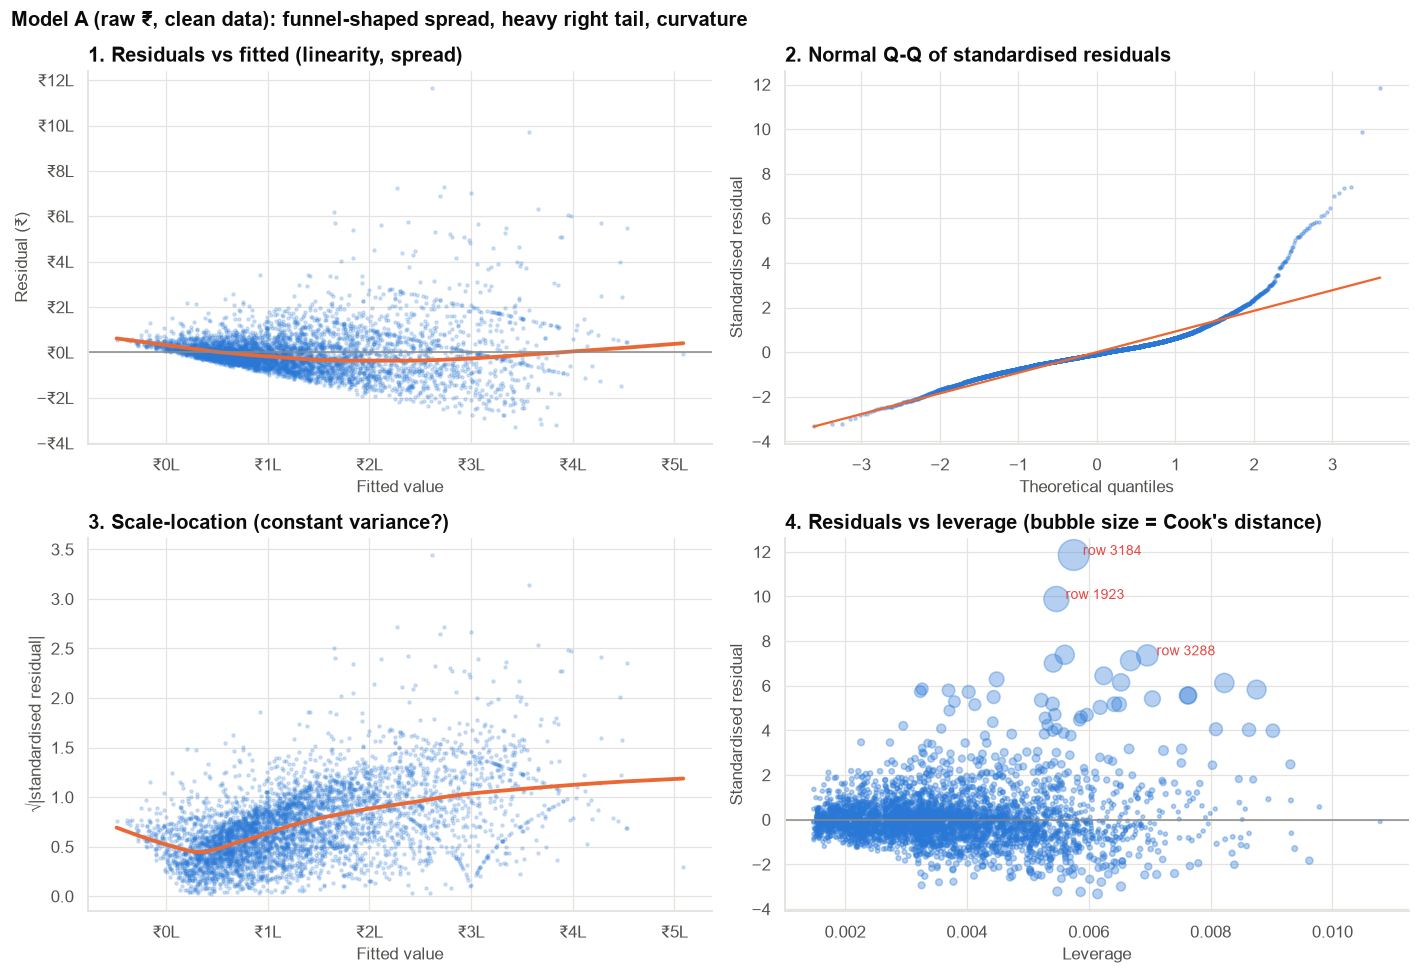

In [7]:
clean = claims[~errors].copy()
test_idx = rng.choice(clean.index, size=1500, replace=False)
test, train = clean.loc[test_idx].copy(), clean.drop(index=test_idx).copy()
print(f"After removing {errors.sum()} errors: {len(clean):,} claims → train {len(train):,} / holdout {len(test):,} "
      f"(the holdout plays the role of the 1,500 open claims)")

m_A = smf.ols(RAW, train).fit()
print(f"\nModel A on clean training data: R² = {m_A.rsquared:.3f}; "
      f"negative fitted costs: {(m_A.fittedvalues < 0).sum()} claims")
bp = het_breuschpagan(m_A.resid, m_A.model.exog)
reset = linear_reset(m_A, power=2, use_f=True)
jb = stats.jarque_bera(m_A.resid)
testsA = pd.DataFrame({"statistic": [bp[2], float(reset.fvalue), jb.statistic],
                       "p_value": [bp[3], float(reset.pvalue), jb.pvalue],
                       "checks": ["constant variance", "functional form (linearity)", "normal residuals"]},
                      index=["Breusch-Pagan (F)", "RESET (F, squared fitted)", "Jarque-Bera"])
save_table(testsA, "assumption_tests_raw", PATHS["tables"])
display(testsA)
diagnostic_panel(m_A, "Model A (raw ₹, clean data): funnel-shaped spread, heavy right tail, curvature", "fig03_diagnostics_raw_clean",
                 y_label="Residual (₹)", money=True)

**Observation.** Even after cleaning, Model A fails every check:
- **Panel 1 (residuals vs fitted):** a **funnel**: spread grows with the fitted value, and the smoothed line curves.
  96 training claims get **negative** predicted costs.
- **Panel 2 (Q-Q):** the upper tail rises far above the line: residuals are strongly right-skewed.
- **Panel 3 (scale-location):** rising: variance increases with the mean.
- **Tests:** Breusch-Pagan, RESET and Jarque-Bera all reject with tiny p-values.

**A note on tests with large n.** With thousands of observations, formal tests reject even trivial departures. Use
them together with the **plots**, which show *how big* and *what shape* the problem is. Here the plots show the
problems are large.

**Panel 4** still shows large Cook's distances, but now for **genuine** expensive claims (cardiac and orthopaedic
claims in suites). They are large only because an additive model with constant spread does not expect them. We keep
them; the fix is a better model, not deletion.

**Interpretation.** The model is wrong in form (effects are multiplicative, not additive) and in its error assumptions
(spread proportional to the mean). Its standard errors and any prediction intervals are unreliable.

## Section 10 — Fix 1: robust standard errors (and why they are not enough)

In [8]:
m_A_hc3 = smf.ols(RAW, train).fit(cov_type="HC3")
terms = ["procedure_category[T.Cardiac]", "procedure_category[T.Oncology]", "room_type[T.Suite]", "preauth_estimated_los", "age", "smoker"]
se_cmp = pd.DataFrame({"coef (₹)": m_A.params[terms], "classical SE": m_A.bse[terms], "HC3 robust SE": m_A_hc3.bse[terms]})
se_cmp["ratio robust / classical"] = se_cmp["HC3 robust SE"] / se_cmp["classical SE"]
save_table(se_cmp, "robust_vs_classical_se", PATHS["tables"])
se_cmp

,coef (₹),classical SE,HC3 robust SE,ratio robust / classical
procedure_category[T.Cardiac],"157,958.5078","5,572.5674","8,422.6437",1.5114
procedure_category[T.Oncology],"196,831.1100","7,206.7674","10,863.4374",1.5074
room_type[T.Suite],"72,383.2104","5,891.8238","8,387.6587",1.4236
preauth_estimated_los,"10,768.5045",738.3603,883.2209,1.1962
age,"1,693.5789",117.4983,140.1132,1.1925
smoker,"9,140.5017","4,058.1184","4,354.7300",1.0731


**Observation.** Heteroscedasticity-consistent (**HC3**) standard errors are larger than the classical ones: by about
50% for cardiac, oncology and suite, whose claims are the most variable, and by 7–20% for the others. The classical
SEs overstate how precisely these effects are known.

**Interpretation.** Robust SEs fix **inference** (p-values, CIs) under heteroscedasticity, without changing the
coefficients. That is often enough for a quick, defensible test. But they do **not** fix the wrong functional form,
the negative predictions, or the prediction intervals. For pricing and reserving we need a better **model**, not just
better standard errors.

## Section 11 — Fix 2: transform the outcome

### 11.1 Which transformation? Box-Cox

The Box-Cox family y^(λ) = (y^λ − 1)/λ includes no transformation (λ = 1), square root (λ = 0.5) and log (λ → 0).
We choose λ by **profile likelihood**: fit the regression for each λ and see which fits best (the Jacobian term makes
the likelihoods comparable across scales).

Box-Cox λ (profile likelihood) = 0.15; 95% CI 0.13 to 0.17


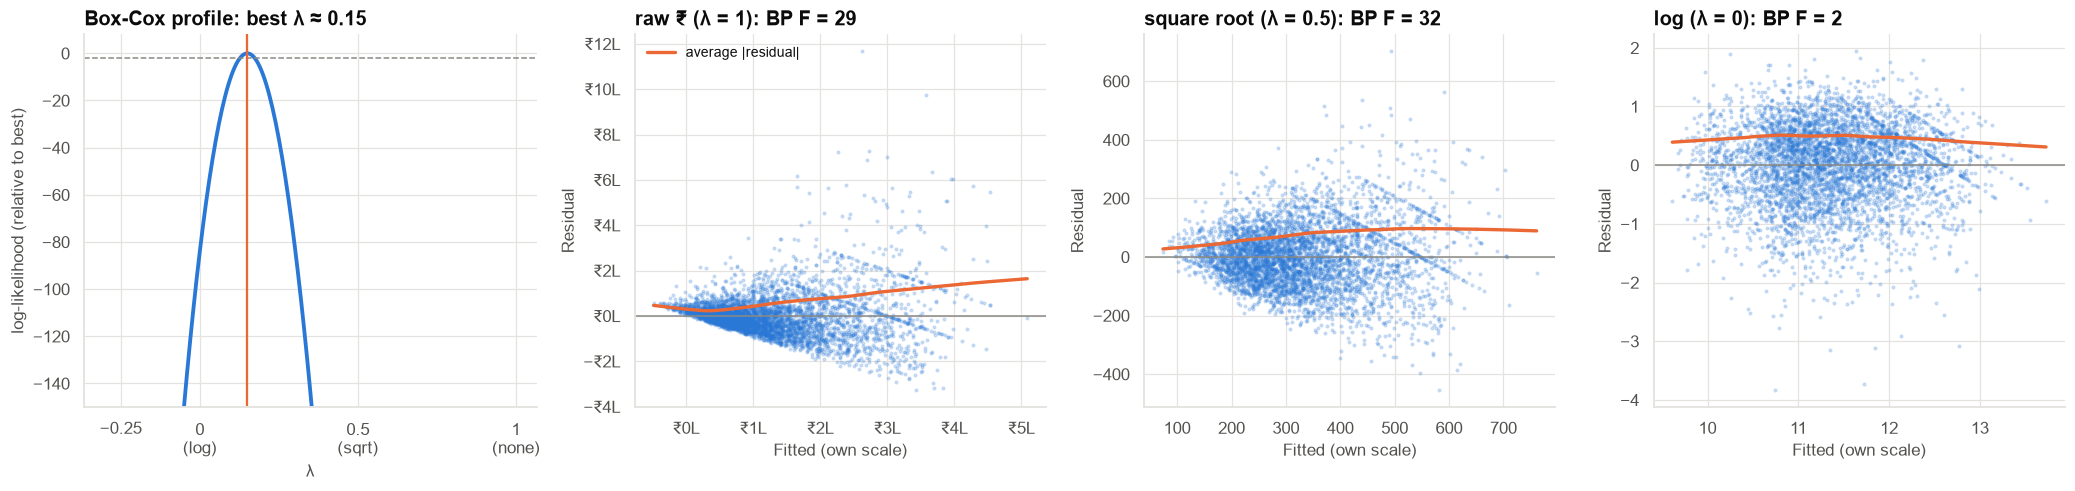

,Breusch-Pagan F,residual skewness,R² (own scale)
raw ₹ (λ = 1),28.5426,2.2083,0.4576
square root (λ = 0.5),32.4347,0.4318,0.5156
log (λ = 0),1.5127,-0.6615,0.4919


In [9]:
y = train["claim_amount"].to_numpy(dtype=float)
X_raw = m_A.model.exog
lams = np.round(np.linspace(-0.3, 1.0, 261), 3)      # steps of 0.005
prof = []
for lam in lams:
    yt = stats.boxcox(y, lmbda=lam)
    ssr = np.sum((yt - X_raw @ np.linalg.lstsq(X_raw, yt, rcond=None)[0]) ** 2)
    prof.append(-len(y) / 2 * np.log(ssr / len(y)) + (lam - 1) * np.log(y).sum())
prof = np.array(prof)
lam_hat = lams[prof.argmax()]
ci_lams = lams[prof >= prof.max() - stats.chi2.ppf(0.95, 1) / 2]
print(f"Box-Cox λ (profile likelihood) = {lam_hat:.2f}; 95% CI {ci_lams.min():.2f} to {ci_lams.max():.2f}")

FORMS = {"raw ₹ (λ = 1)": train["claim_amount"], "square root (λ = 0.5)": np.sqrt(train["claim_amount"]),
         "log (λ = 0)": train["log_claim"]}
rhs = RAW.split("~")[1]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})
ax = axes[0]
ax.plot(lams, prof - prof.max(), color=PRIMARY, lw=2.5)
ax.axhline(-stats.chi2.ppf(0.95, 1) / 2, color=INK_MUTED, ls="--", lw=1)
ax.axvline(lam_hat, color=HIGHLIGHT, lw=1.5)
ax.set_xticks([-0.25, 0, 0.5, 1], ["−0.25", "0\n(log)", "0.5\n(sqrt)", "1\n(none)"])
ax.set_ylim(-150, 8)
ax.set(title=f"Box-Cox profile: best λ ≈ {lam_hat:.2f}", xlabel="λ", ylabel="log-likelihood (relative to best)")
form_tests = {}
for ax, (lab, yy) in zip(axes[1:], FORMS.items()):
    mm = sm.OLS(yy.to_numpy(), X_raw).fit()
    ax.scatter(mm.fittedvalues, mm.resid, s=3, alpha=0.2, color=PRIMARY)
    lw = lowess(np.abs(mm.resid), mm.fittedvalues, frac=0.3)
    ax.plot(lw[:, 0], lw[:, 1], color=HIGHLIGHT, lw=2.2, label="average |residual|")
    ax.axhline(0, color=INK_MUTED, lw=1)
    bpv = het_breuschpagan(mm.resid, X_raw)
    form_tests[lab] = {"Breusch-Pagan F": bpv[2], "residual skewness": stats.skew(mm.resid), "R² (own scale)": mm.rsquared}
    ax.set(title=f"{lab}: BP F = {bpv[2]:.0f}", xlabel="Fitted (own scale)", ylabel="Residual")
    if lab.startswith("raw"):
        ax.xaxis.set_major_formatter(lfmt); ax.yaxis.set_major_formatter(lfmt)
axes[1].legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig04_transformations", PATHS["figures"])
plt.show()
form_tests = pd.DataFrame(form_tests).T
save_table(form_tests, "transformation_comparison", PATHS["tables"])
form_tests

**Observation.** The Box-Cox profile peaks at **λ ≈ 0.15** (95% CI 0.13–0.17), far from 1 (no transform) and 0.5 (square root), and close
to, but not exactly at, 0 (log). On the raw scale the residual spread fans out strongly (Breusch-Pagan F ≈ 29); the
square root does **not** remove the fan (F ≈ 32); on the log scale the spread is even (F ≈ 1.5). Log residuals are
mildly **left**-skewed (≈ −0.7).

**Interpretation.**
- The log transform fixes the main problem, non-constant variance, because effects are multiplicative and the spread
  is proportional to the mean.
- Why is the best λ slightly above 0? Box-Cox looks for the scale on which residuals are **most normal**. Gamma-
  distributed data are left-skewed on the log scale; their most-normal scale is closer to a cube root (λ ≈ 0.33). A
  λ between 0 and 0.33 is the fingerprint of gamma-like data.
- We choose **log** anyway: it is inside the "multiplicative" family, gives % interpretations, and fixes the variance.
  Making residuals perfectly normal is not the goal. The next sections model the gamma directly.

### 11.2 Why the log works: the mean-variance relationship

If the standard deviation is proportional to the mean, the variance grows with the **square** of the mean. A quick
check: group claims by predicted cost and plot log(variance) against log(mean). The slope tells you the family:

| Slope of log variance vs log mean | Variance ∝ | Natural model |
|---|---|---|
| ≈ 0 | constant | Ordinary regression |
| ≈ 1 | mean | Poisson-type (counts, Case 26) |
| ≈ 2 | mean² | **Gamma** GLM, or log-transformed OLS |
| ≈ 3 | mean³ | Inverse Gaussian |

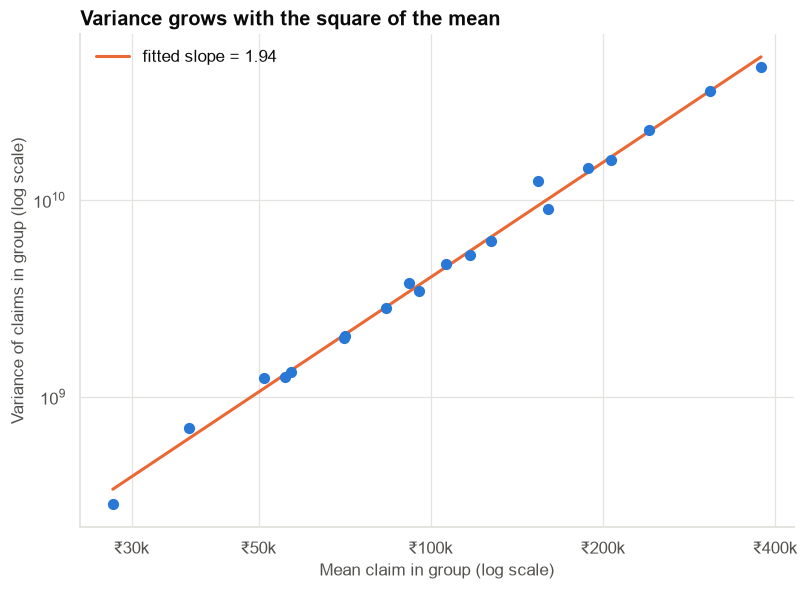

Slope of log(variance) on log(mean) across 20 groups: 1.94


In [10]:
m_tmp = smf.ols("log_claim ~ " + rhs, train).fit()
grp = pd.qcut(m_tmp.fittedvalues, 20, labels=False)
mv = train.groupby(grp)["claim_amount"].agg(["mean", "var"])
slope, intercept = np.polyfit(np.log(mv["mean"]), np.log(mv["var"]), 1)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(mv["mean"], mv["var"], s=40, color=PRIMARY, zorder=3)
xs = np.linspace(mv["mean"].min(), mv["mean"].max(), 20)
ax.plot(xs, np.exp(intercept) * xs ** slope, color=HIGHLIGHT, lw=2, label=f"fitted slope = {slope:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(kfmt); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks([3e4, 5e4, 1e5, 2e5, 4e5])
ax.set(title="Variance grows with the square of the mean", xlabel="Mean claim in group (log scale)",
       ylabel="Variance of claims in group (log scale)")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig05_mean_variance", PATHS["figures"])
plt.show()
print(f"Slope of log(variance) on log(mean) across 20 groups: {slope:.2f}")

**Observation.** The slope is close to **2**: the variance of claims grows with the square of their mean. Equivalently,
the **coefficient of variation is constant**: a cardiac claim's spread in ₹ is large because its mean is large, not
because it is "more random" in relative terms.

**Interpretation.** This is the signature of the **gamma distribution**, the standard model for insurance claim
severity. It explains why the log transform works, and suggests modelling the gamma directly (Section 14).

## Section 12 — Fix 3: the right functional form for age and length of stay

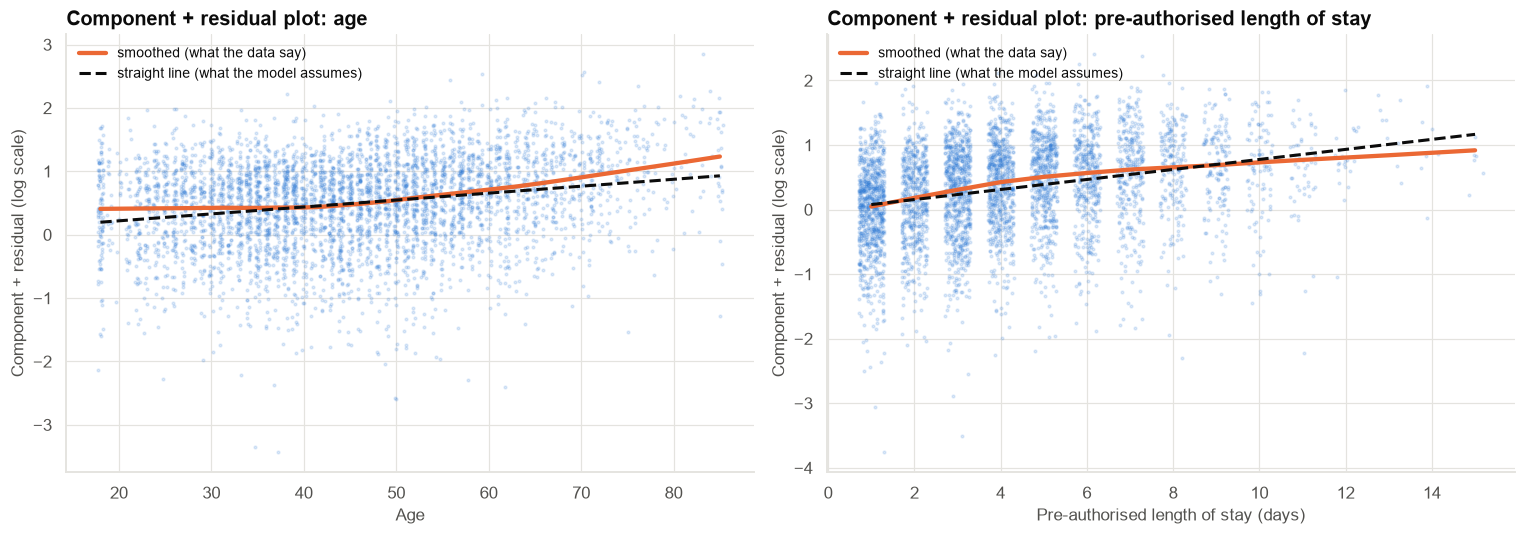

F-test for the age² term: F = 66.3, p = < 0.001


,AIC,adj. R²
"LOS linear, age linear","9,509.9831",0.4902
"log(LOS), age linear","9,455.1815",0.4964
"log(LOS), age + age² (centred)","9,391.1449",0.5036


In [11]:
m_lin = smf.ols("log_claim ~ procedure_category + room_type + hospital_type + preauth_estimated_los + age + smoker + diabetic", train).fit()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, var, lab in zip(axes, ["age", "preauth_estimated_los"], ["Age", "Pre-authorised length of stay (days)"]):
    cr = m_lin.resid + m_lin.params[var] * train[var]          # component + residual
    ax.scatter(train[var] + rng.uniform(-0.3, 0.3, len(train)), cr, s=3, alpha=0.15, color=PRIMARY)
    lw = lowess(cr, train[var], frac=0.4)
    ax.plot(lw[:, 0], lw[:, 1], color=HIGHLIGHT, lw=2.8, label="smoothed (what the data say)")
    xs = np.linspace(train[var].min(), train[var].max(), 20)
    ax.plot(xs, m_lin.params[var] * xs, color=INK, ls="--", lw=2, label="straight line (what the model assumes)")
    ax.set(title=f"Component + residual plot: {lab.split(' (')[0].lower()}", xlabel=lab, ylabel="Component + residual (log scale)")
    ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig06_component_residual", PATHS["figures"])
plt.show()

m_log = smf.ols("log_claim ~ procedure_category + room_type + hospital_type + log_los + age_c + I(age_c**2) + smoker + diabetic", train).fit()
m_log_noq = smf.ols("log_claim ~ procedure_category + room_type + hospital_type + log_los + age_c + smoker + diabetic", train).fit()
form_cmp = pd.DataFrame({"AIC": [m_lin.aic, m_log_noq.aic, m_log.aic], "adj. R²": [m_lin.rsquared_adj, m_log_noq.rsquared_adj, m_log.rsquared_adj]},
                        index=["LOS linear, age linear", "log(LOS), age linear", "log(LOS), age + age² (centred)"])
f_q = m_log.compare_f_test(m_log_noq)
print(f"F-test for the age² term: F = {f_q[0]:.1f}, p = {fmt_p(f_q[1])}")
save_table(form_cmp, "functional_form_comparison", PATHS["tables"])
form_cmp

**Observation.**
- **Length of stay:** the smoothed component-plus-residual curve **bends**: each extra day adds less than the one
  before. log(LOS) fits better (lower AIC) than LOS in days.
- **Age:** the curve bends **upwards** after about 50: costs rise faster for older patients. Adding a **centred**
  age² term improves the fit (F-test p < 0.001, lower AIC).

**Interpretation.** A component-plus-residual (partial residual) plot shows one predictor's relationship with the
outcome after removing the others, with the model's straight-line assumption drawn on top. When the two disagree, the
functional form is wrong. **Centring** age before squaring avoids the structural multicollinearity of Case 09 and
makes the linear term mean "slope at age 45".

## Section 13 — Model B: regression on log(cost), and the retransformation trap

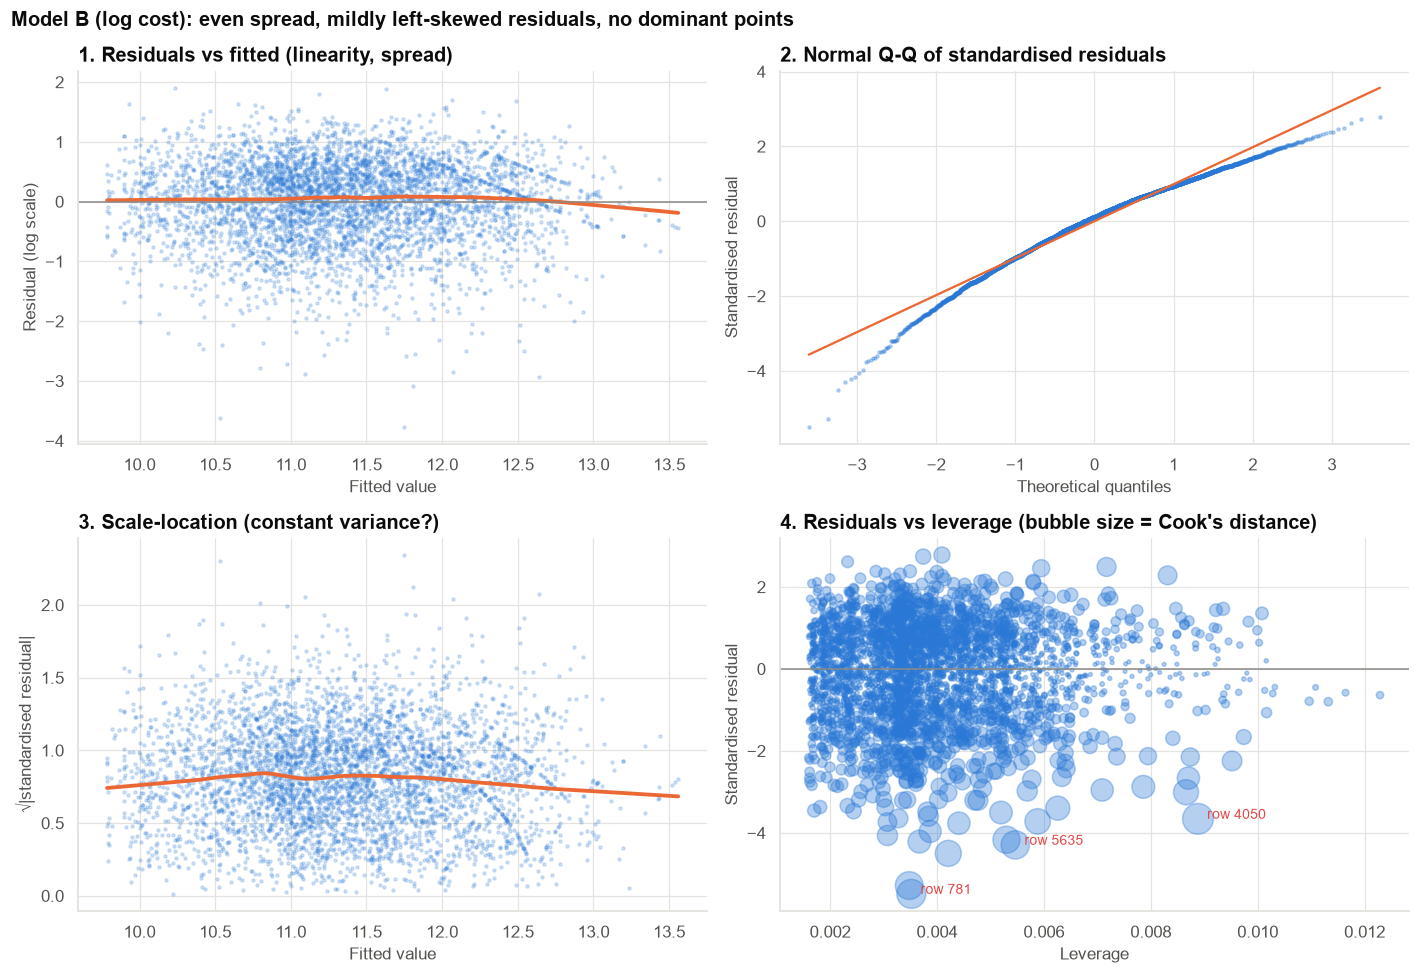

Breusch-Pagan F = 1.21, p = 0.252;  residual skewness = -0.68;  max Cook's D = 0.0071
log(LOS) elasticity: 0.342 (doubling the stay → +27% cost)


,coef,% effect,ci_low %,ci_high %,p_value
procedure_category[T.Day-care],-0.4501,-36.2467,-41.7099,-30.2715,0.0000
procedure_category[T.Maternity],0.0650,6.7154,-0.8907,14.9052,0.0849
procedure_category[T.Surgical],0.5205,68.2908,58.9344,78.1980,0.0000
procedure_category[T.Orthopaedic],0.6418,89.9943,76.7234,104.2617,0.0000
procedure_category[T.Cardiac],1.0231,178.1834,158.0356,199.9044,0.0000
procedure_category[T.Oncology],1.1772,224.5268,194.8823,257.1514,0.0000
room_type[T.Semi-private],0.1092,11.5404,5.8801,17.5033,0.0000
room_type[T.Private],0.2721,31.2739,24.7051,38.1887,0.0000
room_type[T.Suite],0.4481,56.5261,44.4386,69.6252,0.0000
hospital_type[T.Network-non-metro],-0.1108,-10.4890,-14.4695,-6.3233,0.0000


In [12]:
diagnostic_panel(m_log, "Model B (log cost): even spread, mildly left-skewed residuals, no dominant points", "fig07_diagnostics_log",
                 y_label="Residual (log scale)")
bp_log = het_breuschpagan(m_log.resid, m_log.model.exog)
print(f"Breusch-Pagan F = {bp_log[2]:.2f}, p = {bp_log[3]:.3f};  residual skewness = {stats.skew(m_log.resid):+.2f};  "
      f"max Cook's D = {m_log.get_influence().cooks_distance[0].max():.4f}")
ci = m_log.conf_int()
coef_log = pd.DataFrame({"coef": m_log.params, "% effect": pct(m_log.params), "ci_low %": pct(ci[0]), "ci_high %": pct(ci[1]),
                         "p_value": m_log.pvalues}).drop(["Intercept", "age_c", "I(age_c ** 2)", "log_los"])
save_table(coef_log, "log_model_effects", PATHS["tables"])
print(f"log(LOS) elasticity: {m_log.params['log_los']:.3f} (doubling the stay → {pct(m_log.params['log_los'] * np.log(2)):+.0f}% cost)")
coef_log

**Observation.** On the log scale, residuals have even spread (Breusch-Pagan p ≈ 0.25), only mild left skew, and no
claim has a large Cook's distance (max 0.007). The effects are multiplicative and readable: cardiac and oncology
claims cost about 2.8× and 3.2× medical management, a suite about +57% vs a general ward, non-network hospitals about
+8% vs network-metro, diabetics about +7% (p ≈ 0.04), smokers about +5% (p ≈ 0.06, not quite significant), and
doubling the length of stay adds about 27%.

### The retransformation trap: why the log model under-reserved

The log model predicts **E[log cost]**. Taking exp() of that gives the **median** cost, not the **mean**: for a
right-skewed variable, the mean is larger. Reserves and premiums need the **mean** (total money).

Two corrections:
- **Normal theory:** mean = exp(prediction) × exp(σ²/2). Valid only if log residuals are exactly normal.
- **Duan's smearing estimator:** mean = exp(prediction) × average of exp(residual). Uses the actual residuals, no
  normality assumption.

In [13]:
sigma2 = m_log.scale
smear = np.mean(np.exp(m_log.resid))
print(f"σ² of log residuals = {sigma2:.3f}  → normal-theory factor exp(σ²/2) = {np.exp(sigma2 / 2):.3f}")
print(f"Smearing factor = mean(exp(residual)) = {smear:.3f}")
print(f"→ exp(prediction) alone under-predicts the mean by about {1 - 1 / smear:.0%}")

σ² of log residuals = 0.471  → normal-theory factor exp(σ²/2) = 1.266
Smearing factor = mean(exp(residual)) = 1.228
→ exp(prediction) alone under-predicts the mean by about 19%


**Observation.** The smearing factor is about **1.23**: naive exp() predictions are about 19% too low on average.
That is exactly the "log model under-reserves" problem the Appointed Actuary saw.

## Section 14 — Model C: gamma GLM with a log link

A **generalised linear model** (GLM) separates two choices:
- the **link**: log(mean) = Xβ (multiplicative effects, like the log model);
- the **distribution**: gamma (variance ∝ mean², as Section 11.2 found).

Because it models the **mean** directly, no retransformation is needed.

Estimated gamma shape k = 1/dispersion = 2.56  (coefficient of variation = 1/√k = 0.63)

,log-OLS coef,gamma GLM coef,gamma % effect,gamma SE
Intercept,10.4104,10.6446,"4,196,539.7330",0.0343
procedure_category[T.Day-care],-0.4501,-0.4855,-38.4593,0.0416
procedure_category[T.Maternity],0.0650,0.0555,5.7112,0.0344
procedure_category[T.Surgical],0.5205,0.5018,65.1680,0.0266
procedure_category[T.Orthopaedic],0.6418,0.6357,88.8289,0.0336
procedure_category[T.Cardiac],1.0231,1.0102,174.6025,0.0349
procedure_category[T.Oncology],1.1772,1.1146,204.8265,0.0445
room_type[T.Semi-private],0.1092,0.0924,9.6848,0.0242
room_type[T.Private],0.2721,0.2633,30.1247,0.0238
room_type[T.Suite],0.4481,0.4511,57.0115,0.0373


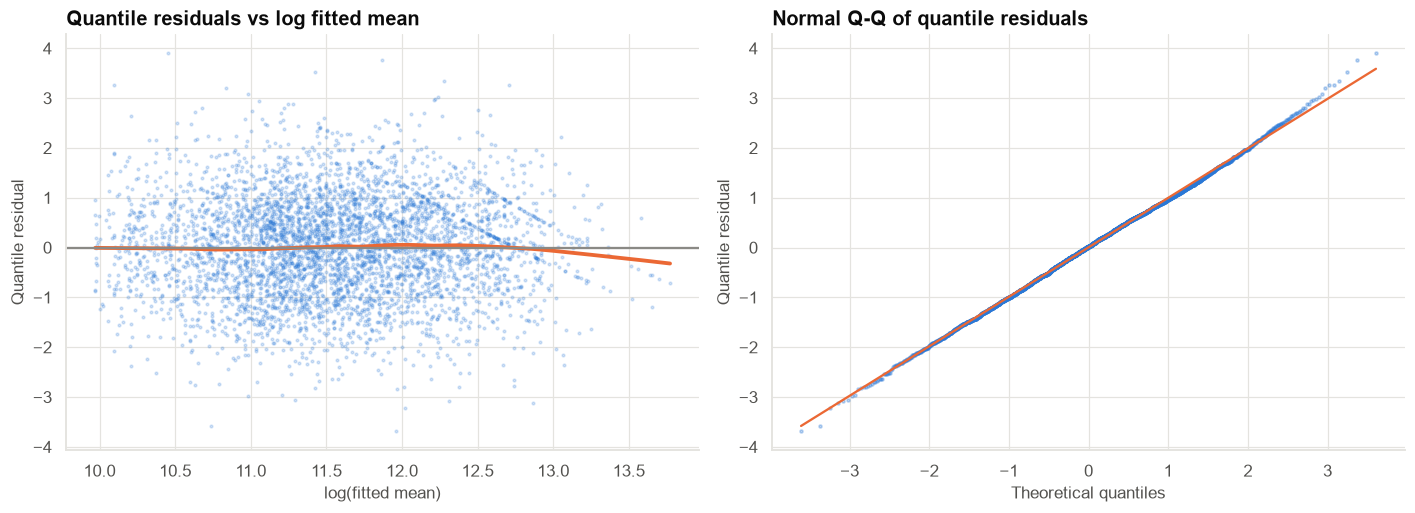

In [14]:
F_GLM = "claim_amount ~ procedure_category + room_type + hospital_type + log_los + age_c + I(age_c**2) + smoker + diabetic"
m_gam = smf.glm(F_GLM, train, family=sm.families.Gamma(sm.families.links.Log())).fit()
shape = 1 / m_gam.scale
print(f"Estimated gamma shape k = 1/dispersion = {shape:.2f}  (coefficient of variation = 1/√k = {1 / np.sqrt(shape):.2f})")
cmp = pd.DataFrame({"log-OLS coef": m_log.params, "gamma GLM coef": m_gam.params,
                    "gamma % effect": pct(m_gam.params), "gamma SE": m_gam.bse})
save_table(cmp, "log_ols_vs_gamma", PATHS["tables"])
display(cmp)

# Randomised quantile residuals: exactly standard normal if the gamma model is right.
qres = stats.norm.ppf(np.clip(stats.gamma.cdf(train["claim_amount"], a=shape, scale=m_gam.fittedvalues / shape), 1e-6, 1 - 1e-6))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(np.log(m_gam.fittedvalues), qres, s=3, alpha=0.2, color=PRIMARY)
lw = lowess(qres, np.log(m_gam.fittedvalues), frac=0.3)
axes[0].plot(lw[:, 0], lw[:, 1], color=HIGHLIGHT, lw=2.5)
axes[0].axhline(0, color=INK_MUTED)
axes[0].set(title="Quantile residuals vs log fitted mean", xlabel="log(fitted mean)", ylabel="Quantile residual")
stats.probplot(qres, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=2, alpha=0.3, color=PRIMARY); axes[1].get_lines()[1].set(color=HIGHLIGHT)
axes[1].set(title="Normal Q-Q of quantile residuals", xlabel="Theoretical quantiles", ylabel="Quantile residual")
fig.tight_layout()
save_fig(fig, "fig08_gamma_diagnostics", PATHS["figures"])
plt.show()

**Observation.** The gamma GLM's coefficients are very close to the log-OLS coefficients (both estimate multiplicative
effects). Its shape parameter is about 2.6, i.e. a coefficient of variation of about 0.63. **Quantile residuals**
(which are standard normal if the model is right) lie on the Q-Q line except at the extreme upper end, where the
**sum-insured cap** truncates the largest claims, and show even spread across fitted values.

**Log-OLS or gamma GLM?**

| | Log-OLS | Gamma GLM (log link) |
|---|---|---|
| Effects | Multiplicative | Multiplicative |
| Predicts | E[log y] → needs smearing for the mean | E[y] directly |
| Assumes | Normal errors on log scale | Variance ∝ mean² |
| Handles zeros | No | No (use Tweedie for zero claims) |
| Best for | Quick analysis; medians | **Pricing and reserving totals** |

## Section 15 — Holdout comparison: which model reserves correctly?

The 1,500 holdout claims play the role of the open claims. A model's job for reserving is to get the **total** right,
and the totals within segments (procedures) right. For gamma we also apply the **cap**: the insurer pays
E[min(cost, sum insured)], which for a gamma distribution has an exact formula.

In [15]:
def gamma_capped_mean(mu, k, cap):
    # E[min(Y, cap)] for Y ~ Gamma(shape k, mean mu): mu·F_{k+1}(cap) + cap·(1 − F_k(cap)).
    theta = mu / k
    return mu * stats.gamma.cdf(cap, a=k + 1, scale=theta) + cap * stats.gamma.sf(cap, a=k, scale=theta)

pred = pd.DataFrame(index=test.index)
pred["A: OLS on raw ₹"] = m_A.predict(test)
pred["B: log-OLS, naive exp()"] = np.exp(m_log.predict(test))
pred["B: log-OLS + smearing"] = np.exp(m_log.predict(test)) * smear
pred["C: gamma GLM"] = m_gam.predict(test)
pred["C: gamma GLM + cap"] = gamma_capped_mean(m_gam.predict(test), shape, test["sum_insured"])
actual = test["claim_amount"]

def metrics(p):
    seg = pd.DataFrame({"a": actual, "p": p, "g": test["procedure_category"]}).groupby("g", observed=True)[["a", "p"]].sum()
    return {"predicted total": p.sum(), "total vs actual (%)": 100 * (p.sum() / actual.sum() - 1),
            "worst procedure total error (%)": 100 * (seg["p"] / seg["a"] - 1).abs().max(),
            "MAE (₹)": (actual - p).abs().mean(), "negative predictions": int((p < 0).sum())}
hold = pd.DataFrame({k: metrics(v) for k, v in pred.items()}).T
print(f"Actual total paid on the 1,500 holdout claims: {crore(actual.sum())}")
save_table(hold, "holdout_comparison", PATHS["tables"])
hold

Actual total paid on the 1,500 holdout claims: ₹18.67 Cr


,predicted total,total vs actual (%),worst procedure total error (%),MAE (₹),negative predictions
A: OLS on raw ₹,"195,450,102.7524",4.7079,12.8351,"61,548.8434",33.0000
"B: log-OLS, naive exp()","159,790,664.0168",-14.3958,22.1823,"54,891.6527",0.0000
B: log-OLS + smearing,"196,224,311.9047",5.1227,12.7400,"57,101.0826",0.0000
C: gamma GLM,"195,182,439.6398",4.5645,12.0904,"56,875.3588",0.0000
C: gamma GLM + cap,"186,555,444.6059",-0.0572,10.3109,"55,948.1939",0.0000


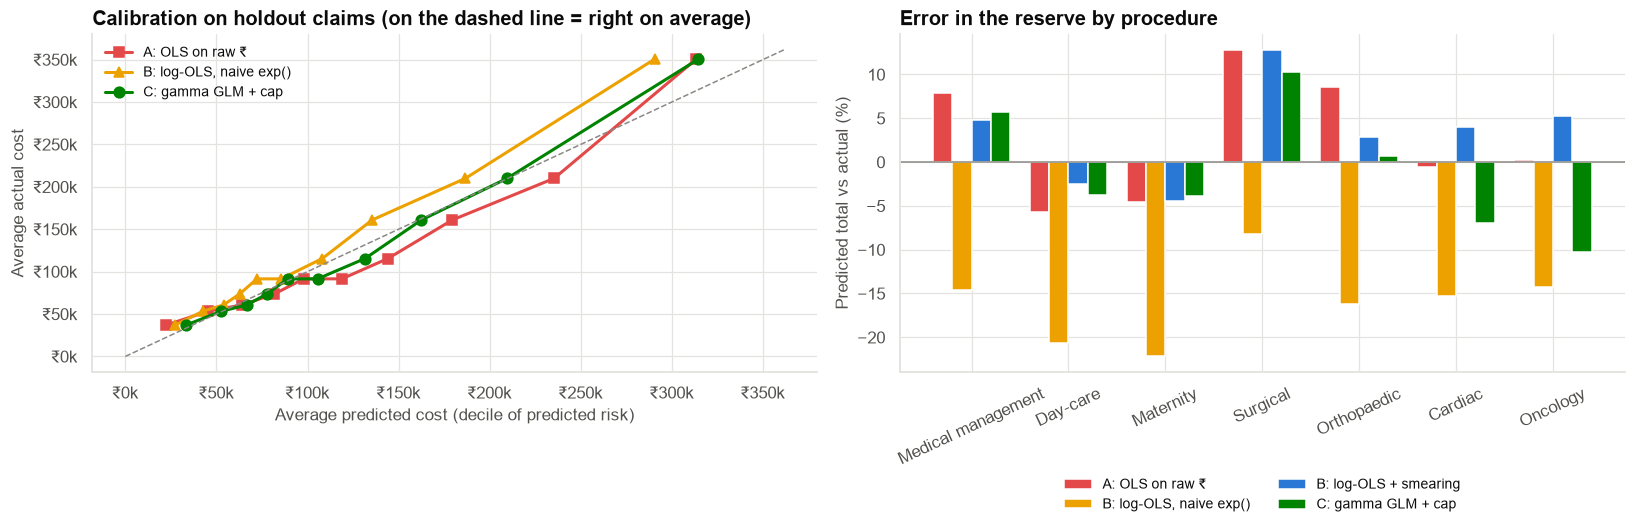

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
dec = pd.qcut(pred["C: gamma GLM + cap"], 10, labels=False)
for k, col, mk in [("A: OLS on raw ₹", COLORS["red"], "s"), ("B: log-OLS, naive exp()", COLORS["yellow"], "^"),
                   ("C: gamma GLM + cap", COLORS["green"], "o")]:
    g = pd.DataFrame({"a": actual, "p": pred[k], "d": dec}).groupby("d").mean()
    ax.plot(g["p"], g["a"], marker=mk, ms=7, lw=2, color=col, label=k)
lims = [0, pred["C: gamma GLM + cap"].groupby(dec).mean().max() * 1.15]
ax.plot(lims, lims, color=INK_MUTED, ls="--", lw=1)
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(kfmt)
ax.set(xlabel="Average predicted cost (decile of predicted risk)", ylabel="Average actual cost",
       title="Calibration on holdout claims (on the dashed line = right on average)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax = axes[1]
seg = pd.DataFrame({"a": actual, "g": test["procedure_category"]}).join(pred).groupby("g", observed=True).sum()
models_show = ["A: OLS on raw ₹", "B: log-OLS, naive exp()", "B: log-OLS + smearing", "C: gamma GLM + cap"]
xs = np.arange(len(seg))
for i, (k, col) in enumerate(zip(models_show, [COLORS["red"], COLORS["yellow"], PRIMARY, COLORS["green"]])):
    ax.bar(xs + (i - 1.5) * 0.2, 100 * (seg[k] / seg["a"] - 1), width=0.2, color=col, label=k)
ax.axhline(0, color=INK_MUTED, lw=1)
ax.set_xticks(xs, seg.index, rotation=25)
ax.set(ylabel="Predicted total vs actual (%)", title="Error in the reserve by procedure")
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
fig.tight_layout()
save_fig(fig, "fig09_holdout_calibration", PATHS["figures"])
plt.show()

**Observation.**
- **Model B with naive exp()** under-predicts the total by about **14%**, and every procedure by 8–22%: the
  under-reserving the Appointed Actuary saw.
- **Model A (raw OLS)**, **log-OLS + smearing** and the **uncapped gamma GLM** all over-predict the total by about
  **5%**. They predict what claims would cost **without** the sum-insured limit, but the insurer never pays above it.
- **Gamma + cap** predicts E[min(cost, sum insured)] and gets the total right (−0.1%).
- By procedure, no model is perfect: even gamma + cap is off by up to about 10% (surgical, oncology), which with
  100–400 claims per procedure is partly noise.
- Raw OLS's acceptable total hides problems: 33 negative predictions, poor calibration (it over-predicts mid-range
  claims and under-predicts the top decile, left panel), the highest MAE, and invalid intervals. A total that is
  right by accident is fragile: a change in case mix moves it.

## Section 16 — How much to reserve, and how uncertain?

The reserve is a **sum** of 1,500 uncertain claims. Its uncertainty has two sources: randomness of each claim
(gamma noise) and uncertainty in the model's coefficients. We simulate both: draw coefficients from their estimated
sampling distribution, then draw every claim from the gamma distribution, capped at its sum insured.

,value,₹ crore
best estimate (expected total),"186,555,444.6059",18.6555
median of simulated totals,"186,512,773.8572",18.6513
5th percentile,"180,665,479.3379",18.0665
95th percentile,"192,721,417.3614",19.2721
99.5th percentile,"196,589,890.0097",19.6590
"ACTUAL total paid (known here, unknown in real life)","186,662,190.0000",18.6662


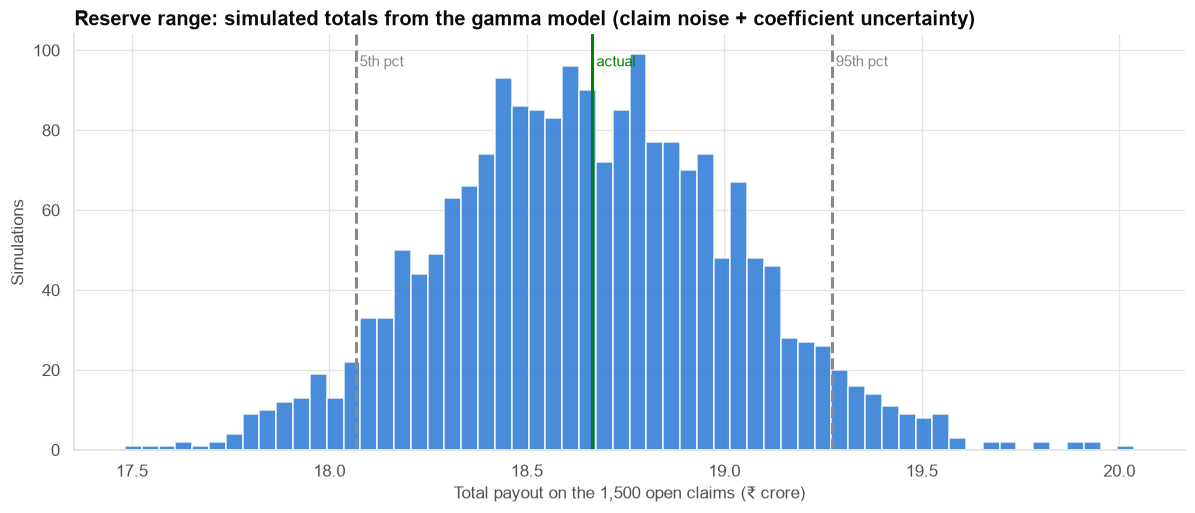

In [17]:
# Design matrix of the open claims, built with the same formula (categorical levels are fixed, so columns match).
test_model = smf.glm(F_GLM, test, family=sm.families.Gamma(sm.families.links.Log()))
assert list(test_model.exog_names) == list(m_gam.params.index)
X_test = test_model.exog
beta_draws = rng.multivariate_normal(m_gam.params.to_numpy(), m_gam.cov_params().to_numpy(), size=2000)
cap = test["sum_insured"].to_numpy()
totals = np.empty(len(beta_draws))
for i, b in enumerate(beta_draws):
    mu = np.exp(X_test @ b)
    totals[i] = np.minimum(rng.gamma(shape, mu / shape), cap).sum()
lo, mid, hi = np.percentile(totals, [5, 50, 95])
p995 = np.percentile(totals, 99.5)
res = pd.DataFrame({"value": [hold.loc["C: gamma GLM + cap", "predicted total"], mid, lo, hi, p995, actual.sum()]},
                   index=["best estimate (expected total)", "median of simulated totals", "5th percentile", "95th percentile",
                          "99.5th percentile", "ACTUAL total paid (known here, unknown in real life)"])
res["₹ crore"] = res["value"] / 1e7
save_table(res, "reserve_range", PATHS["tables"])
display(res)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hist(totals / 1e7, bins=60, color=PRIMARY, alpha=0.85)
for v, lab, col in [(lo, "5th pct", INK_MUTED), (hi, "95th pct", INK_MUTED), (actual.sum(), "actual", COLORS["green"])]:
    ax.axvline(v / 1e7, color=col, lw=2, ls="--" if lab != "actual" else "-")
    ax.text(v / 1e7, ax.get_ylim()[1] * 0.95, f" {lab}", color=col, fontsize=10, va="top")
ax.set(xlabel="Total payout on the 1,500 open claims (₹ crore)", ylabel="Simulations",
       title="Reserve range: simulated totals from the gamma model (claim noise + coefficient uncertainty)")
fig.tight_layout()
save_fig(fig, "fig10_reserve_range", PATHS["figures"])
plt.show()

**Observation.** The best estimate of the total is about **₹18.7 crore**, with a 90% range of about ₹18.1–19.3 crore
(roughly ±3%) and a 99.5th percentile of about ₹19.7 crore. The actual total paid on these claims (₹18.7 crore) is
almost exactly the best estimate; being that close is partly luck, but landing inside the range is what the model
promises.

**Interpretation.** Because the reserve is a sum of many claims, its relative uncertainty is far smaller than any
single claim's: individual claims vary by about ±60%, the total by only a few percent. Regulatory capital rules ask
for high percentiles (such as 99.5%) of this kind of distribution.

**Caveat.** The simulation assumes the gamma model is right, including its tail. Real portfolios also have rare
catastrophic claims and claim-cost inflation, which a model fitted on past claims does not capture. Actuaries add
explicit loadings for these.

## Section 17 — Decision framework: what each diagnostic result means

| You see… | It means… | Do this |
|---|---|---|
| Funnel in residuals vs fitted; rising scale-location line; Breusch-Pagan rejects | Variance grows with the mean | For inference only: **HC3 robust SEs**. For prediction/intervals: transform Y (log) or use a GLM (gamma) |
| Curve in residuals vs fitted, or in a component-plus-residual plot; RESET rejects | Wrong functional form | Transform X (log, polynomial, spline), add interactions; re-check |
| Q-Q: points bend up at the right | Right-skewed errors | Log/Box-Cox transform Y, or gamma/log-normal model. With large n, inference is OK, prediction intervals are not |
| Q-Q: both tails outside the lines | Heavy tails | Robust regression, t-errors, or check for outliers |
| A few points with Cook's D far above the rest | Influential observations | Check them against **business rules**; fix or remove errors; keep genuine extremes; report with/without |
| Box-Cox λ near 0 / near 0.5 / near 1 | Log / square root / no transform | Prefer the interpretable choice near the optimum; λ between 0 and ⅓ suggests gamma-like data |
| log(variance) vs log(mean) slope ≈ 2 | Constant coefficient of variation | **Gamma** GLM (log link) |
| Negative predictions for a positive outcome | Additive model for a multiplicative process | Log link (log-OLS or GLM) |
| You need the mean in ₹ from a log model | exp() gives the median | **Smearing** factor, or fit a GLM |
| Outcome capped (sum insured, credit limit) | Large values are cut off | Predict E[min(Y, cap)]; censored-data models if the cap binds often |
| Formal test rejects, plot looks fine (large n) | Trivial departure | Judge by size of the problem, not the p-value |

## Section 18 — Results

In [18]:
gam_eff = pct(m_gam.params)
summary = pd.DataFrame({"Value": [
    f"{errors.sum()} claims keyed in paise (×100); found by Cook's distance and the sum-insured rule",
    f"R² {m_A.rsquared:.2f}; {(m_A.fittedvalues < 0).sum()} negative predictions; all assumption tests rejected",
    f"λ = {lam_hat:.2f} (95% CI {ci_lams.min():.2f} to {ci_lams.max():.2f}) → log",
    f"slope {slope:.2f} → gamma; shape k = {shape:.2f}",
    f"{smear:.2f} → naive exp() under-predicts by {1 - 1 / smear:.0%}",
    f"cardiac {gam_eff['procedure_category[T.Cardiac]']:+.0f}%, oncology {gam_eff['procedure_category[T.Oncology]']:+.0f}%, "
    f"suite {gam_eff['room_type[T.Suite]']:+.0f}%, smoker {gam_eff['smoker']:+.0f}%",
    f"raw OLS {hold.loc['A: OLS on raw ₹', 'total vs actual (%)']:+.1f}% (worst procedure {hold.loc['A: OLS on raw ₹', 'worst procedure total error (%)']:.0f}%); "
    f"naive log {hold.loc['B: log-OLS, naive exp()', 'total vs actual (%)']:+.1f}%; gamma + cap {hold.loc['C: gamma GLM + cap', 'total vs actual (%)']:+.1f}%",
    f"best estimate {crore(hold.loc['C: gamma GLM + cap', 'predicted total'])}; 90% range {crore(lo)} – {crore(hi)}; actual {crore(actual.sum())}",
]}, index=["Data errors", "Model A (raw ₹)", "Box-Cox", "Mean-variance", "Smearing factor", "Gamma effects",
           "Holdout totals", "Reserve (1,500 open claims)"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Data errors,6 claims keyed in paise (×100); found by Cook'...
Model A (raw ₹),R² 0.46; 96 negative predictions; all assumpti...
Box-Cox,λ = 0.15 (95% CI 0.13 to 0.17) → log
Mean-variance,slope 1.94 → gamma; shape k = 2.56
Smearing factor,1.23 → naive exp() under-predicts by 19%
Gamma effects,"cardiac +175%, oncology +205%, suite +57%, smo..."
Holdout totals,raw OLS +4.7% (worst procedure 13%); naive log...
"Reserve (1,500 open claims)",best estimate ₹18.66 Cr; 90% range ₹18.07 Cr –...


## Section 19 — Interpretation

- **The raw-₹ regression was the wrong model**, not just a noisy one: claim costs are multiplicative and their spread
  is proportional to their mean. That produced the funnel, the skewed residuals, the negative predictions and the
  poor fit.
- **Six data-entry errors** dominated the first model. Diagnostics found them; a business-rule check would have found
  them sooner.
- **Robust standard errors** rescue p-values but not predictions.
- **The log model was right in shape but wrong in level**: exp() of a log prediction is a median. The smearing factor
  (≈ 1.23) explains the actuary's under-reserving.
- **Getting the mean right is not enough: the cap matters.** Smearing and the gamma GLM both predict uncapped costs and
  over-reserve by about 5%. Applying the sum-insured cap to the gamma model brings the holdout total to within 0.1%.
- **The gamma GLM** (log link) matches the data's mean-variance structure (slope ≈ 1.94) and predicts the mean directly.

## Section 20 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Cardiac claims cost about 2.7× medical-management claims on average, for similar patients, rooms and hospitals." | "A cardiac claim will cost ₹X" (individual claims vary by about ±60%). |
| "The expected total for the open claims is about ₹18.7 crore, with a 90% range of about ±3%." | "We will pay exactly ₹18.66 crore." |
| "Non-network hospitals are associated with about 10% higher costs than network-metro ones." | "Moving patients to network hospitals will cut costs by 10%" (patients and cases differ in ways we don't observe; Case 21). |
| "The raw-₹ model's assumptions fail; its p-values are unreliable." | "Since all tests reject, nothing can be learned." (The log/gamma models pass the checks that matter.) |

## Section 21 — Business interpretation

- **Pricing:** use the gamma GLM's multiplicative relativities (procedure, room, hospital, age curve, smoker,
  diabetic). They are stable and well-diagnosed.
- **Reserving:** hold the gamma + cap estimate for open claims, with the simulated range as the basis for the
  risk margin. The naive log model would have under-reserved by about 14%; models that ignore the cap over-reserve by
  about 5%.
- **Data quality:** add a load-time rule that rejects claim amounts above the sum insured.

## Section 22 — Limitations

- Synthetic data with a known gamma process; real severity data often have heavier tails (log-normal or Pareto for the
  largest claims).
- The gamma model is fitted to capped claims; with only a few percent capped, the bias is small but not zero.
- No claim inflation, seasonality or reporting delays (IBNR) are modelled.
- Effects are associations, not causes (Case 21).

## Section 23 — Final recommendation

> **Replace the raw-₹ regression with a gamma GLM with a log link** (age as a centred quadratic, length of stay on the
> log scale), applying the sum-insured cap to predictions. **Reserve the model's expected total for the 1,500 open
> claims** and use the simulated distribution for the risk margin. **Fix the six paise-entry records** and add a
> sum-insured validation rule at data load.

## Section 24 — What would I do next?

1. Test **heavier-tailed** alternatives for the largest claims (log-normal, a separate large-loss model above a
   threshold).
2. Add **claim inflation** and reporting-delay (IBNR) adjustments with the reserving team.
3. Monitor model **calibration by procedure** each quarter, using the decile and segment plots from Section 15.
4. Use a **Tweedie** model if pricing moves to cost per policy (including zero-claim policies).
5. Continue to **Case 11** (logistic regression for churn) for a binary outcome, and **Case 26** for counts and
   time-to-event.